# Метрическое обучение: triplet loss для идентификации лиц

Учебный курс «Программирование глубоких нейронных сетей на Python».

До сих пор мы решали задачу **классификации**: сеть предсказывала номер одного из фиксированных классов.
Но во многих приложениях нужно узнавать **конкретного человека** (распознавание лиц), находить похожие
изображения или понимать, «этот человек или другой». Классификация для этого плохо подходит:

* чтобы добавить нового человека, классификатор приходится переобучать;
* классификатор не умеет просто сравнивать два фото между собой.

Решение — **метрическое обучение** (metric learning): вместо вероятностей классов сеть учится сопоставлять
входному изображению **вектор-эмбеддинг**. В этом векторном пространстве расстояние отражает «похожесть»:
фото одного человека лежат близко, фото разных людей — далеко. Проверка «этот или другой» сводится
к сравнению расстояния с порогом, а узнавание человека — к поиску ближайшего соседа в базе эталонов.

Для обучения таких эмбеддингов используется **триплетная потеря** (triplet loss), с которой мы и поработаем.

<a target="_blank" href="https://colab.research.google.com/github/kirilman/dlpython_course/blob/master/12_metric_learning/triplet_loss_identification.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Постановка задачи

Мы построим «систему идентификации человека по лицу». Сеть учится строить **эмбеддинги**, для которых
расстояние между фото одного человека мало, а между фото разных людей — велико. Обучение идёт сразу на
фотографиях **всех 40 человек** набора, без деления на «знакомых» и «незнакомцев»: модель просто учится
отвечать на вопрос «на фото этот человек или другой».

Проверяем систему на тех же людях двумя способами:

* **верификация**: по паре фото ответить, один ли это человек (метрика — AUC);
* **идентификация**: несколько эталонных фото каждого человека кладём в «галерею», а по остальным фото
  ищем человека с **ближайшим эмбеддингом** (метрика — точность распознавания).

## Данные: Olivetti faces

Набор [Olivetti faces](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html):
40 человек по 10 чёрно-белых фотографий размером 64×64. Каждая фотография — анфас с лёгкими вариациями
мимики и освещения. Набор маленький (400 изображений), поэтому любой шаг обучается за секунды.

In [1]:
# Установка библиотек (в Colab большинство уже есть)
# !pip install -q torch scikit-learn matplotlib

import torch
import torch.nn as nn
import numpy as np
import random
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces

# Выбираем устройство и фиксируем генераторы случайных чисел
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Загрузка набора данных (кэшируется в папку data/)
faces = fetch_olivetti_faces(data_home='data', shuffle=True, random_state=42)

# Изображения оставляем в виде отдельного канала: (400, 1, 64, 64)
X = torch.tensor(faces.images)[:, None]
y = torch.tensor(faces.target)                # номер человека 0..39

print('Форма изображений:', tuple(X.shape))
print('Число людей в наборе:', int(torch.unique(y).shape[0]))
print('Фотографий на человека:', int(len(X) / torch.unique(y).shape[0]))

Устройство: cuda
Форма изображений: (400, 1, 64, 64)
Число людей в наборе: 40
Фотографий на человека: 10


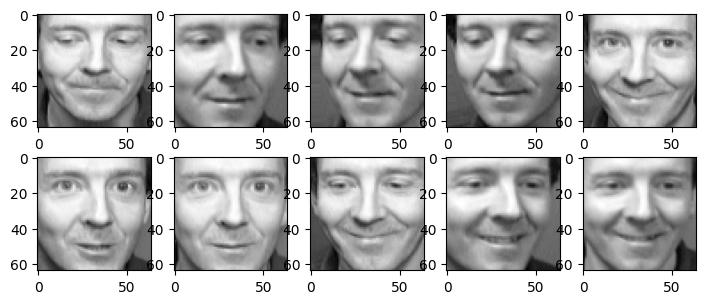

In [2]:
rows=2
cols=5
plt.figure(figsize=(cols * 1.7, rows * 1.7))
for k, img in enumerate(X[torch.where(y == 2)]):
    plt.subplot(rows, cols, k+1)
    plt.imshow(img[0], cmap='gray')  

### Посмотрим на фотографии

У каждого человека фото похожи, но отличаются деталями — именно эти различия модель должна игнорировать,
сохраняя главное: «это один и тот же человек».

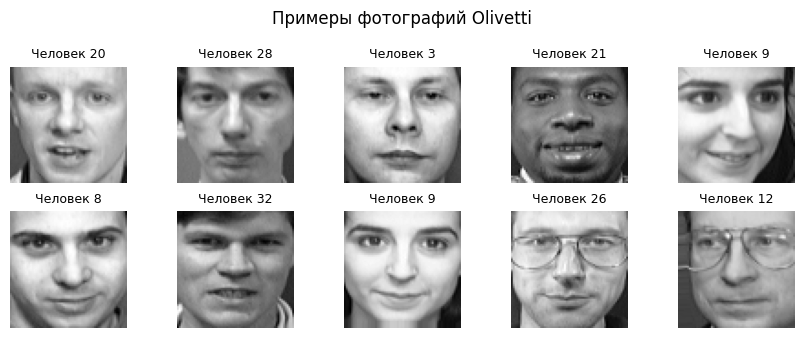

In [3]:
def show_faces(images, targets, rows=2, cols=5, title=''):
    plt.figure(figsize=(cols * 1.7, rows * 1.7))
    for i in range(rows * cols):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i], cmap='gray')
        plt.title(f'Человек {targets[i]}', fontsize=9)
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

show_faces(faces.images, faces.target, rows=2, cols=5, title='Примеры фотографий Olivetti')

## Данные для обучения

Обучаемся сразу на всех 40 людях — разделения на «знакомых» и «незнакомцев» нет. Для triplet loss
достаточно того, что мы умеем выбирать тройки: фото одного человека, другое фото того же человека и
фото любого другого человека.

In [4]:
all_idx = torch.arange(len(X))     # используем все фотографии всех 40 людей

print('Людей в наборе:', int(torch.unique(y).shape[0]))
print('Всего фотографий:', len(all_idx))

Людей в наборе: 40
Всего фотографий: 400


## Архитектура: свёрточная сеть-эмбеддинг

Сеть принимает фото 64×64 и выдаёт вектор фиксированной размерности (128) — **эмбеддинг**.
Последний слой дополнен **L2-нормировкой**: вектор всегда единичной длины, поэтому евклидово
расстояние между эмбеддингами однозначно соответствует косинусной близости.

Структура: четыре блока `Conv2d + BatchNorm + ReLU + MaxPool` (64 → 4 пикселя) и линейный слой.

In [5]:
class EmbeddingNet(nn.Module):
    """Свёрточная сеть, сопоставляющая фото человека вектору-эмбеддингу."""

    def __init__(self, embedding_dim=128):
        super().__init__()

        def conv_block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1),
                nn.BatchNorm2d(c_out),
                nn.ReLU(),
                nn.MaxPool2d(2))

        self.features = nn.Sequential(
            conv_block(1, 32),
            conv_block(32, 64),
            conv_block(64, 128),
            conv_block(128, 128),
        )
        self.head = nn.Linear(128 * 4 * 4, embedding_dim)

    def forward(self, x):
        x = self.features(x).flatten(1)
        x = self.head(x)
        return nn.functional.normalize(x, dim=1)     # нормируем на единичную сферу

torch.manual_seed(42)          # сид прямо перед инициализацией весов
net = EmbeddingNet().to(device)
print('Параметров в сети:', f"{sum(p.numel() for p in net.parameters()):,}")

with torch.no_grad():
    net.eval()
    sample = net(X[:8].to(device))
    print('Форма эмбеддинга:', tuple(sample.shape), '| норма:', float(sample.norm(dim=1).mean()))

Параметров в сети: 503,232
Форма эмбеддинга: (8, 128) | норма: 1.0


Форма эмбеддинга: (8, 128) | норма: 1.0


## Triplet loss

Обучение описывается тройками изображений — **триплетами**:

* **anchor (якорь)** — исходное фото;
* **positive** — другое фото того же человека;
* **negative** — фото другого человека.

Нужно, чтобы расстояние до positive было меньше расстояния до negative хотя бы на величину
**margin** (запас):

$$L = \max\left(d(a, p) - d(a, n) + \text{margin},\; 0\right)$$

Если модель уже хорошо разделяет людей, слагаемое под максимумом отрицательно и потеря равна нулю.
Только «плохие» тройки дают ошибку и «подталкивают» эмбеддинги в нужную сторону.

### Собираем триплеты: batch-hard mining

Триплеты лучше не брать случайно, а выбирать самые «сложные» в мини-выборке. Для этого набираем батч
из **P человек по K фотографий** каждого, а для каждого якоря берём:

* самый **далёкий** positive того же человека (`hard positive`);
* самый **близкий** negative другого человека (`hard negative`).

Это стандартный приём из работы [FaceNet](https://arxiv.org/abs/1503.03832), он ускоряет обучение.

In [103]:
P, K = 8, 4          # 8 человек по 4 фото в каждом батче

def make_batch(person_labels, P, K):
    """Случайно выбирает P разных людей и по K фотографий каждого."""
    people = torch.unique(person_labels)
    chosen = people[torch.randperm(len(people))[:P]]
    ids = []
    for person in chosen:
        candidate = (person_labels == person).nonzero().flatten()
        ids.append(candidate[torch.randperm(len(candidate))[:K]])
    return torch.cat(ids)


def batch_hard_triplets(emb, labels):
    """Для каждого якоря находит самого сложного positive и negative в батче."""
    dist = torch.cdist(emb, emb)                     # попарные расстояния
    same = labels[:, None] == labels[None, :]
    eye = torch.eye(len(labels), dtype=torch.bool, device=emb.device)
    pos_mask = same & ~eye                           # фото одного человека (не само себя)
    neg_mask = ~same                                 # фото разных людей

    hardest_pos = emb[dist.masked_fill(~pos_mask, -float('inf')).argmax(1)]
    hardest_neg = emb[dist.masked_fill(~neg_mask, float('inf')).argmin(1)]
    return emb, hardest_pos, hardest_neg #Наимеее похожий их своих, наиболее похожий из чужик фотографий

triplet_loss = nn.TripletMarginLoss(margin=0.2)

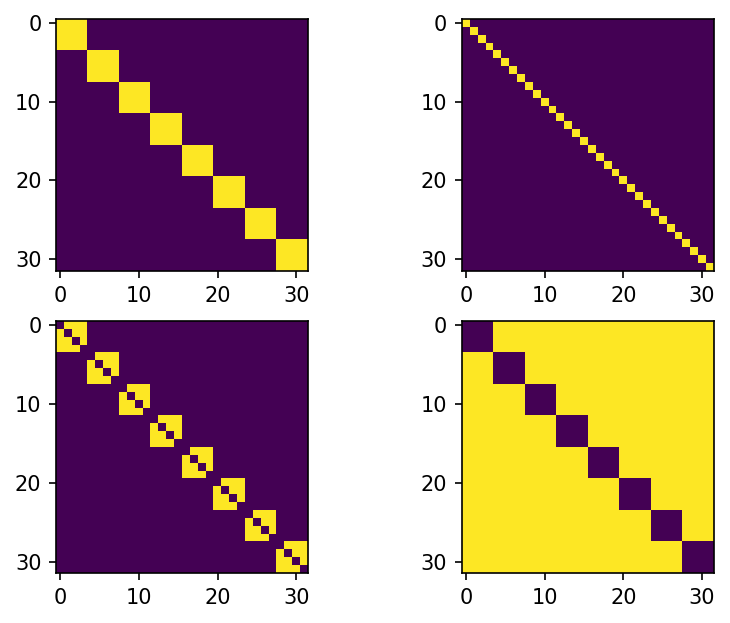

In [102]:
same = yb[:, None] == yb[None, :]
eye = torch.eye(len(yb), dtype=torch.bool, device=yb.device)
pos_mask = same & ~eye                          
neg_mask = ~same   
fig,ax = plt.subplots(2,2, dpi = 150)
ax[0,0].imshow(same.detach().cpu())
ax[0,1].imshow(eye.detach().cpu())
ax[1,0].imshow(pos_mask.detach().cpu())
ax[1,1].imshow(neg_mask.detach().cpu())

In [83]:
def make_batch(person_labels, P, K):
    """Случайно выбирает P разных людей и по K фотографий каждого."""
    people = torch.unique(person_labels)
    chosen = people[torch.randperm(len(people))[:P]]
    ids = []
    for person in chosen:
        candidate = (person_labels == person).nonzero().flatten()
        print(candidate)
        ids.append(candidate[torch.randperm(len(candidate))[:K]])
    return torch.cat(ids)
    
ids = make_batch(y, P, K)
xb = X[ids].to(device)
yb = y[ids].to(device)

tensor([128, 148, 163, 167, 221, 301, 329, 353, 367, 375])
tensor([  9,  60, 172, 182, 190, 205, 234, 241, 306, 391])
tensor([ 43,  48, 124, 179, 233, 244, 263, 296, 373, 393])
tensor([ 85, 103, 115, 171, 178, 184, 256, 290, 304, 308])
tensor([ 10,  24,  72,  80, 105, 150, 228, 280, 307, 337])
tensor([  4,   7,  89, 170, 173, 176, 269, 288, 343, 386])
tensor([ 14, 107, 110, 141, 223, 250, 303, 305, 356, 383])
tensor([ 15,  50,  73, 254, 275, 291, 312, 330, 338, 369])


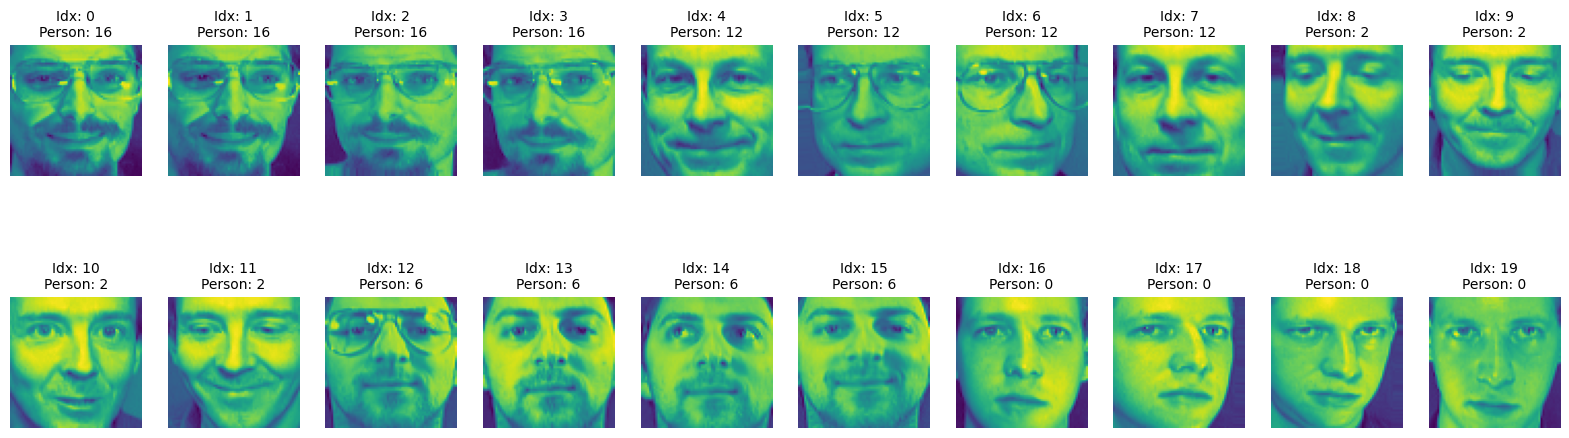

In [84]:
fig = plt.figure(figsize=(20, 6))
max_items = 20
rows = 2
cols = 10
for k, (label, img) in enumerate(zip(yb, xb)):
    if k >= max_items:
        break
    ax = fig.add_subplot(rows, cols, k + 1)
    ax.imshow(img[0].detach().cpu().numpy())
    ax.axis('off')
    ax.set_title(f"Idx: {k}\nPerson: {label}", fontsize=10)

## Функции оценки

* **верификация** — по всем парам фото считаем AUC: насколько хорошо расстояния разделяют пары
  «один человек» от пар «разные люди»;
* **идентификация** — несколько эталонных фото каждого человека кладём в «галерею», остальные фото
  служат запросами: для запроса ищем **ближайший по расстоянию эмбеддинг** в галерее и берём его
  человека. Особый случай с одним эталоном на человека называют **one-shot**.

In [7]:
N_REF = 2          # сколько эталонных фото на человека кладём в «галерею»


@torch.no_grad()
def embed_images(net, idx):
    """Эмбеддинги всех изображений по индексам."""
    net.eval()
    return net(X[idx].to(device)).cpu()


def verification_metrics(net, idx):
    """AUC верификации и распределения расстояний «свой» / «чужой»."""
    from sklearn.metrics import roc_auc_score

    emb = embed_images(net, idx)
    yy = y[idx]
    dist = torch.cdist(emb, emb)
    same = yy[:, None] == yy[None, :]
    upper = torch.triu(torch.ones_like(same, dtype=torch.bool), 1)   # берём половину матрицы

    same_dist = dist[upper & same].numpy()
    diff_dist = dist[upper & ~same].numpy()
    auc = roc_auc_score(np.r_[np.ones(len(same_dist)), np.zeros(len(diff_dist))],
                        -np.r_[same_dist, diff_dist])
    return auc, same_dist, diff_dist


@torch.no_grad()
def identification_accuracy(net, idx, n_ref=N_REF):
    """Точность идентификации: n_ref фото на человека идут в «галерею»
    эталонов, а остальные фото — запросы. Каждое фото-запрос относится
    к человеку с самым близким (по расстоянию) эмбеддингом галереи."""
    emb = embed_images(net, idx)
    yy = y[idx]

    gallery_emb, gallery_lab, query_emb, query_lab = [], [], [], []
    for person in torch.unique(yy):
        loc = (yy == person).nonzero().flatten()
        gallery_emb.append(emb[loc[:n_ref]]); gallery_lab.append(yy[loc[:n_ref]])
        query_emb.append(emb[loc[n_ref:]]);   query_lab.append(yy[loc[n_ref:]])

    gallery_emb = torch.cat(gallery_emb); gallery_lab = torch.cat(gallery_lab)
    query_emb = torch.cat(query_emb);     query_lab = torch.cat(query_lab)

    dist = torch.cdist(query_emb, gallery_emb)          # расстояние до всех эталонов
    pred = gallery_lab[dist.argmin(1)]                  # ближайший эталон -> человек
    return (pred == query_lab).float().mean().item()

### Оценка «до обучения»

Эмбеддинги случайной (необученной) сети: расстояния «свой» и «чужой» почти не различаются.
Запомним эти числа, а также сохраним копию необученной сети для визуализации.

In [8]:
import copy

# Метрики до обучения
auc0, same0, diff0 = verification_metrics(net, all_idx)
ident0 = identification_accuracy(net, all_idx)

net_init = copy.deepcopy(net)     # копия с необученными весами — для сравнения

print(f'Верификация (AUC) до обучения:          {auc0:.3f}')
print(f'Идентификация (галерея {N_REF} фото):       {100 * ident0:.1f}%')
print(f'Расстояние «свой» / «чужой»:            {same0.mean():.3f} / {diff0.mean():.3f}')

Верификация (AUC) до обучения:          0.871
Идентификация (галерея 2 фото):       67.2%
Расстояние «свой» / «чужой»:            0.064 / 0.103


## Обучение

Каждый шаг: набираем мини-выборку `P×K`, вычисляем эмбеддинги, для каждого якоря находим
сложнейшие positive/negative и применяем `TripletMarginLoss`. С каждым шагом «свой» человек
подтягивается ближе, а «чужой» — отталкивается.

Эпоха  60 | средняя ошибка 0.0000 | AUC 1.000


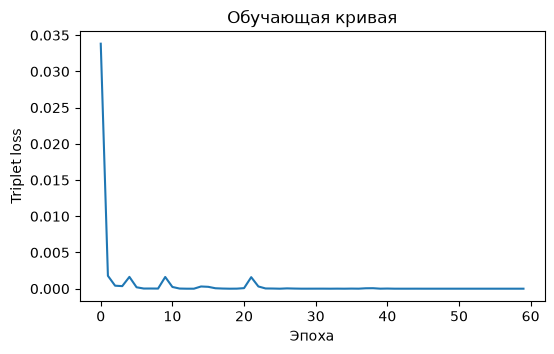

In [ ]:
EPOCHS = 60
BATCHES_PER_EPOCH = 200

optimizer = torch.optim.Adam(net.parameters(), lr=2e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

train_losses = []
for epoch in range(EPOCHS):
    net.train()
    epoch_loss = 0.0
    for _ in range(BATCHES_PER_EPOCH):
        ids = make_batch(y, P, K)
        xb = X[ids].to(device)
        yb = y[ids].to(device)

        emb = net(xb)
        a, p, n = batch_hard_triplets(emb, yb)
        loss = triplet_loss(a, p, n)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    scheduler.step()
    train_losses.append(epoch_loss / BATCHES_PER_EPOCH)

    if (epoch + 1) % 20 == 0:
        auc_cur = verification_metrics(net, all_idx)[0]
        print(f'Эпоха {epoch + 1:3d} | средняя ошибка {train_losses[-1]:.4f} | AUC {auc_cur:.3f}')

plt.figure(figsize=(6, 3.5))
plt.plot(train_losses)
plt.xlabel('Эпоха')
plt.ylabel('Triplet loss')
plt.title('Обучающая кривая')
plt.show()

## Результаты

Сравним метрики — до и после обучения.

In [10]:
auc1, same1, diff1 = verification_metrics(net, all_idx)
ident1 = identification_accuracy(net, all_idx)

print('                                    ДО        ПОСЛЕ')
print(f'Верификация (AUC):                {auc0:5.3f}      {auc1:5.3f}')
print(f'Идентификация (галерея {N_REF} фото):     {100 * ident0:5.1f}%     {100 * ident1:5.1f}%')
print(f'Расстояние «свой»:               {same0.mean():5.3f}      {same1.mean():5.3f}')
print(f'Расстояние «чужой»:              {diff0.mean():5.3f}      {diff1.mean():5.3f}')

                                    ДО        ПОСЛЕ
Верификация (AUC):                0.871      1.000
Идентификация (галерея 2 фото):      67.2%     100.0%
Расстояние «свой»:               0.064      0.270
Расстояние «чужой»:              0.103      1.333


### Гистограммы расстояний

До обучения распределения «свой» и «чужой» сильно перекрываются — по расстоянию нельзя сказать,
один это человек или разные. После обучения между ними появляется заметный разрыв.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, same_d, diff_d, title in [
        (axes[0], same0, diff0, 'До обучения'),
        (axes[1], same1, diff1, 'После обучения')]:
    ax.hist(diff_d, bins=40, alpha=0.6, color='tab:red', label='разные люди')
    ax.hist(same_d, bins=40, alpha=0.6, color='tab:blue', label='один человек')
    ax.set_xlabel('расстояние между эмбеддингами')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

### Визуализация эмбеддингов: t-SNE

Спроецируем 128-мерные эмбеддинги всех 40 человек на плоскость методом
[t-SNE](https://scikit-learn.org/stable/modules/manifold.html#t-sne).
После обучения точки одного человека собираются в один кластер, а разные люди разделяются.

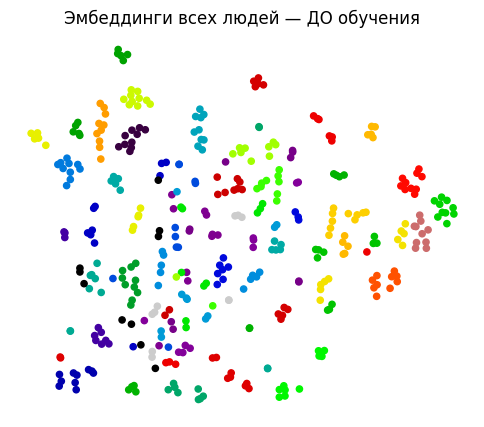

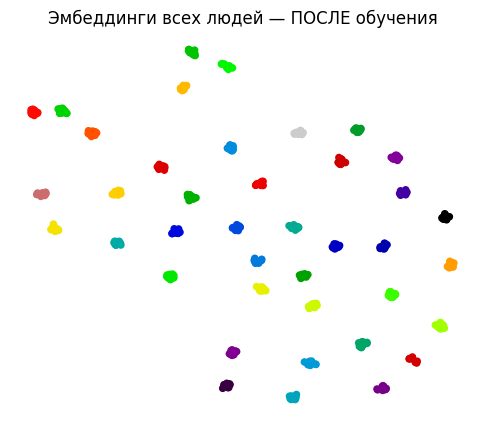

In [12]:
from sklearn.manifold import TSNE

def tsne_scatter(net_eval, idx, title):
    emb = embed_images(net_eval, idx).numpy()
    emb2d = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(emb)
    plt.figure(figsize=(6, 5))
    plt.scatter(emb2d[:, 0], emb2d[:, 1], c=y[idx].numpy(), cmap='nipy_spectral', s=20)
    plt.title(title)
    plt.axis('off')
    plt.show()

tsne_scatter(net_init, all_idx, 'Эмбеддинги всех людей — ДО обучения')
tsne_scatter(net, all_idx, 'Эмбеддинги всех людей — ПОСЛЕ обучения')

### Распознавание в действии

Соберём «галерею» из нескольких эталонных фото каждого человека и для фото-запроса выведем три
**ближайших по расстоянию** эмбеддинга с их людьми. Обученная сеть уверенно ставит своего человека
на первое место (top-1).

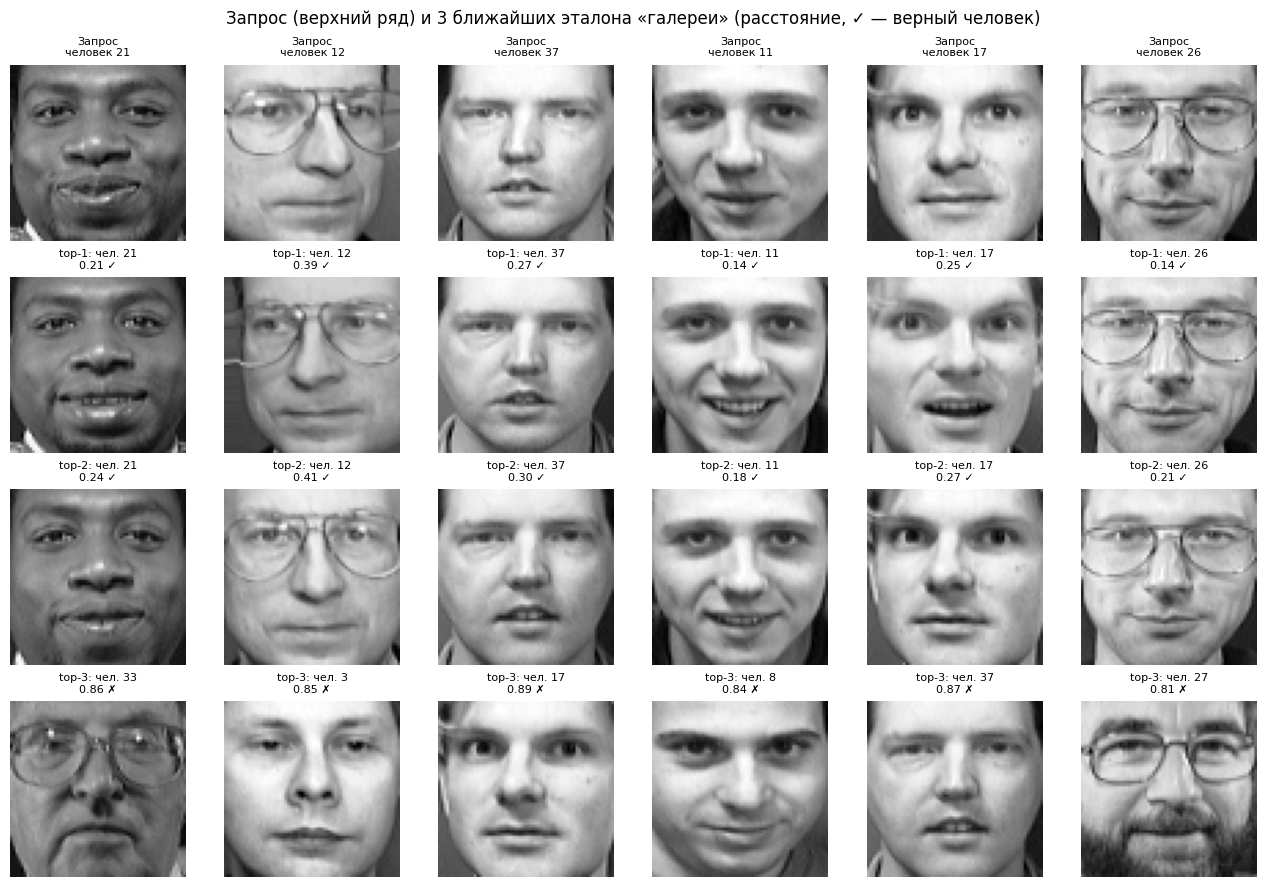

In [14]:
# Собираем «галерею»: по N_REF эталонных фото на каждого человека
gallery_idx, gallery_person = [], []
for person in torch.unique(y):
    loc = (y == person).nonzero().flatten()
    gallery_idx += loc[:N_REF].tolist()
    gallery_person += [int(person)] * N_REF

gallery_emb = embed_images(net, torch.tensor(gallery_idx))
query_idx = torch.tensor([i for i in all_idx.tolist() if i not in set(gallery_idx)])

rng = np.random.RandomState(1)
queries = rng.choice(query_idx.numpy(), 6, replace=False)


@torch.no_grad()
def nearest_in_gallery(net, q, n=3):
    """n ближайших по расстоянию эталонов галереи для фото-запроса q."""
    q_emb = embed_images(net, torch.tensor([int(q)]))
    d = torch.cdist(q_emb, gallery_emb)[0]
    top = d.topk(n, largest=False).indices
    return [(gallery_idx[int(t)], gallery_person[int(t)], float(d[t])) for t in top]


fig, axes = plt.subplots(4, 6, figsize=(13, 9))
for k, q in enumerate(queries):
    axes[0, k].imshow(faces.images[q], cmap='gray')
    axes[0, k].set_title(f'Запрос\nчеловек {int(y[q])}', fontsize=8)
    axes[0, k].axis('off')
    for j, (gi, gp, dist) in enumerate(nearest_in_gallery(net, q)):
        ok = gp == int(y[q])
        axes[j + 1, k].imshow(faces.images[gi], cmap='gray')
        axes[j + 1, k].set_title(f'top-{j + 1}: чел. {gp}\n{dist:.2f} {"✓" if ok else "✗"}', fontsize=8)
        axes[j + 1, k].axis('off')
plt.suptitle('Запрос (верхний ряд) и 3 ближайших эталона «галереи» (расстояние, ✓ — верный человек)')
plt.tight_layout()
plt.show()